# Renovation provenance and quantity changes

Keep physical changes and external assessment references inspectable without importing an external catalogue.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW.

## Understanding the API in this lesson

`SourceRecord` documents evidence for an input field and `ProvenanceSpec` collects those records. `DatasetReference` and `AssessmentReference` identify caller-owned sources and assessment context; constructing them does not fetch factors, prices or catalogue entries.

`RenovationRecord` joins a dated measure, before/after hashes and typed `QuantityChange` entries. The pipeline diagram's physical-quantity branch shows where the material evidence comes from. Administrative provenance and physical identity are distinct so a corrected source citation need not masquerade as a new physical building.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


### A renovation retains both identity and physical changes

The record links the transformation to its evidence while quantity_takeoff measures physical material quantities. The before/after mass plot below is calculated from both specifications. A mass change is not embodied carbon: assessment references still require applicable factors and lifecycle boundaries.

The following original diagram is conceptual API guidance; the later charts and tables report the computed example values.

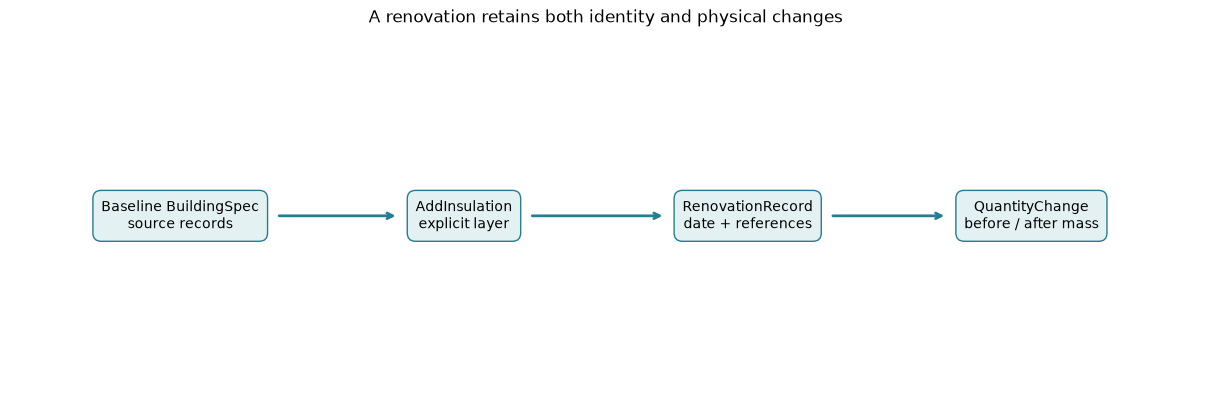

In [2]:
from demo.support.common import flow
flow(['Baseline BuildingSpec\nsource records', 'AddInsulation\nexplicit layer', 'RenovationRecord\ndate + references', 'QuantityChange\nbefore / after mass'], 'A renovation retains both identity and physical changes', figsize=(12, 4))

## Record assumptions and references

SourceRecord captures input evidence. DatasetReference and AssessmentReference identify caller-owned data without fetching prices or emission factors.

### Read the code and output

The confidence value is a caller-supplied statement, not a score calculated by EPSM. The illustrative factor reference has no numerical carbon factor attached. Inspect these fields when reusing the record: a reference name alone does not establish that a lifecycle calculation has been performed.

In [3]:
b=building()
source=SourceRecord(field_path="envelope.wall",status="assumed",source="illustrative assembly",confidence=.5,assumption_profile="demo")
provenance=ProvenanceSpec(records=(source,))
b=b.updated(provenance=provenance)
dataset=DatasetReference(dataset="illustrative-materials",version="demo-1",item_id="wool")
assessment=AssessmentReference(identifier="illustrative-A1-A3",lifecycle_stage="A1-A3",factor_source=dataset)
table(source.model_dump()); table(assessment.model_dump())

,field,value
0,field_path,envelope.wall
1,status,assumed
2,source,illustrative assembly
3,confidence,0.5
4,assumption_profile,demo


,field,value
0,identifier,illustrative-A1-A3
1,currency,None
2,price_base_year,None
3,lifecycle_stage,A1-A3
4,factor_source,"{'dataset': 'illustrative-materials', 'version..."


,field,value
0,identifier,illustrative-A1-A3
1,currency,None
2,price_base_year,None
3,lifecycle_stage,A1-A3
4,factor_source,"{'dataset': 'illustrative-materials', 'version..."


## Apply an audited change

Administrative provenance alone must not alter physical identity. A material change must alter it and retain typed before/after quantity records.

### Read the code and output

The hash assertion changes only provenance and expects physical identity to remain stable. Adding insulation then changes physical inputs and produces before/after quantity evidence. A `QuantityChange` can contain only one side for added or removed items, so interpret null before/after entries according to the action.

In [4]:
assert b.physical_hash()==b.updated(provenance=ProvenanceSpec()).physical_hash()
changed=apply_renovation(b,AddInsulation(element="wall",layer=b.envelope.wall.layers[0].updated(thickness_m=.1)),effective_date="2026-01-01",dataset_references=(dataset,),assessment_references=(assessment,))
record=changed.renovations[-1]
assert isinstance(record,RenovationRecord)
assert all(isinstance(c,QuantityChange) for c in record.changes)
table([{ "action":c.action,"before_kg":c.before.mass_kg if c.before else None,"after_kg":c.after.mass_kg if c.after else None} for c in record.changes])

,action,before_kg,after_kg
0,added,None,268.8
1,added,None,268.8
2,added,None,268.8
3,added,None,179.2
4,added,None,179.2
5,added,None,179.2
6,added,None,268.8
7,added,None,268.8
8,added,None,268.8
9,added,None,179.2


,action,before_kg,after_kg
0,added,None,268.8
1,added,None,268.8
2,added,None,268.8
3,added,None,179.2
4,added,None,179.2
5,added,None,179.2
6,added,None,268.8
7,added,None,268.8
8,added,None,268.8
9,added,None,179.2


## Reconcile physical totals

Only physical quantities are computed here. Attaching a factor reference does not calculate carbon or cost.

### Read the code and output

The mass difference is a physical result of the supplied layer, density and affected area. It is not automatically embodied carbon or cost. The JSON roundtrip verifies that the edited input and audit remain serializable for an external assessment workflow.

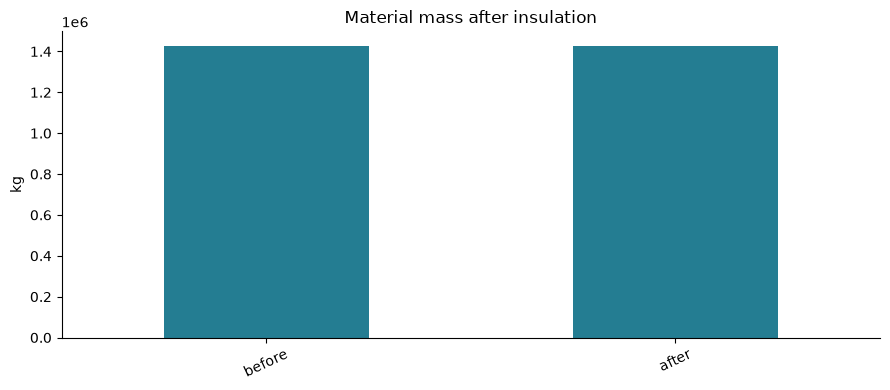

In [5]:
old=sum(q.mass_kg or 0 for q in quantity_takeoff(b)); new=sum(q.mass_kg or 0 for q in quantity_takeoff(changed))
assert new>old
bars({"before":old,"after":new},"kg","Material mass after insulation")
(OUT/"renovated.json").write_text(changed.model_dump_json(indent=2))
assert BuildingSpec.model_validate_json((OUT/"renovated.json").read_text())==changed

## Interpretation and next experiment

Provenance and physical identity serve different purposes. Retain both so a stock result can be traced to assumptions and reassessed with different external factors.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.